In [1]:
import pandas as pd

df_news = pd.read_json("data/news_clean.json")

df_news.head()

,id,content,domain
0,news_vnexpress_02532,Thủ tướng dâng hương tại Nghĩa trang liệt sĩ q...,tin_tuc
1,news_vnexpress_04521,Nhiều tài xế bị phạt vì không đặt biển cảnh bá...,tin_tuc
2,news_vnexpress_61976,Cần Thơ khai quật hai vị trí nghi chôn 12 liệt...,tin_tuc
3,news_vnexpress_59846,"Chủ tịch xã, phường được phạt vi phạm đất đai ...",tin_tuc
4,news_vnexpress_90576,Loạt dự án chống ngập Hà Nội tăng tốc về đích\...,tin_tuc


In [3]:
news_text = df_news.iloc[0]['content']

In [33]:
import pandas as pd 
df_news_chunk = pd.read_json("data/chunking/news_chunks.json")

df_news_chunk.head()

,id,parent_id,chunk_index,domain,content
0,news_vnexpress_02532_0,news_vnexpress_02532,0,tin_tuc,"Tại lễ dâng hương, Thủ tướng và lãnh đạo bộ ng..."
1,news_vnexpress_02532_1,news_vnexpress_02532,1,tin_tuc,Nghĩa trang liệt sĩ quốc gia Vị Xuyên được khở...
2,news_vnexpress_02532_2,news_vnexpress_02532,2,tin_tuc,"Theo Bộ Chỉ huy quân sự tỉnh Tuyên Quang, tron..."
3,news_vnexpress_02532_3,news_vnexpress_02532,3,tin_tuc,"Sáng cùng ngày, Thủ tướng Lê Minh Hưng và đoàn..."
4,news_vnexpress_02532_4,news_vnexpress_02532,4,tin_tuc,"Thủ tướng khẳng định, Đảng, Nhà nước và nhân d..."


In [30]:
df_news_chunk[['content']].describe()

,content
count,74419
unique,71676
top,"Năm 2026, Tổng liên đoàn Lao động Việt Nam và ..."
freq,23


In [28]:
df_news_chunk["num_words"] = (
    df_news_chunk["content"]
    .str.split()
    .str.len()
)

df_news_chunk["num_words"].describe()

count    74419.000000
mean        48.987208
std         23.127104
min         10.000000
25%         32.000000
50%         47.000000
75%         63.000000
max        203.000000
Name: num_words, dtype: float64

In [25]:
text = 'Đến nay, VietinBank đón nhận nhiều giải thưởng trong nước và quốc tế: 14 năm liên tiếp Top 2.000 doanh nghiệp lớn nhất thế giới (Forbes); 7 lần liên tiếp trong Top 300 Thương hiệu ngân hàng giá trị nhất thế giới (Brand Finance); 8 lần liên tiếp được vinh danh là Thương hiệu quốc gia; 5 năm liên tiếp Ngân hàng SME tốt nhất Việt Nam (The Asian Banker); 9 năm liên tiếp Ngân hàng Bán lẻ tốt nhất Việt Nam (Global Banking & Finance Review); Ngân hàng và Ngân hàng số dành cho doanh nghiệp tốt nhất Việt Nam 2024 (IFM); Giải thưởng Sao Khuê 2025 với 5 sản phẩm số tiêu biểu, đặc biệt VietinBank iPay Mobile lần thứ 8 liên tiếp Top 10 Sao'

len(text.split(' '))

128

In [34]:
# Số từ của mỗi chunk
df_news_chunk["num_words"] = df_news_chunk["content"].str.split().str.len()

# Giá trị min và max
min_len = df_news_chunk["num_words"].min()
max_len = df_news_chunk["num_words"].max()

print(f"Min words: {min_len}")
print(f"Max words: {max_len}")

print("\n===== SHORTEST =====")
print(
    df_news_chunk[df_news_chunk["num_words"] == min_len][
        ["id", "num_words", "content"]
    ].to_string(index=False)
)

print("\n===== LONGEST =====")
print(
    df_news_chunk[df_news_chunk["num_words"] == max_len][
        ["id", "num_words", "content"]
    ].to_string(index=False)
)

Min words: 30
Max words: 293

===== SHORTEST =====
                     id  num_words                                                                                                                                                                                       content
 news_vnexpress_59846_0         30                                                          Chính phủ đã ban hành Nghị định 281 ngày 13/7 sửa đổi, bổ sung một số quy định về xử phạt vi phạm hành chính trong lĩnh vực đất đai.
 news_vnexpress_09667_2         30                                                           Ở Lâm Đồng, Nguyễn Thị Bảo Nhi cũng nhận được sự động viên từ người dân địa phương khi bày tỏ mong muốn tham gia công việc ở cơ sở.
 news_vnexpress_09667_9         30                                                           Theo Tuấn, người làm công tác ở cơ sở phải hiểu hoàn cảnh của từng hộ dân để xử lý những việc rất gần gũi trong đời sống hằng ngày.
news_vnexpress_25321_11         30               

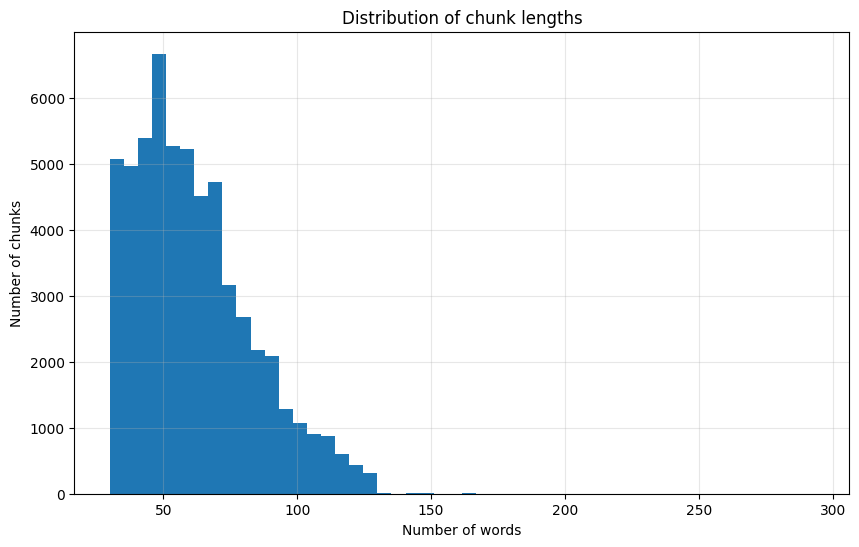

In [35]:
import matplotlib.pyplot as plt

# Tính số từ
df_news_chunk["num_words"] = (
    df_news_chunk["content"]
    .str.split()
    .str.len()
)

plt.figure(figsize=(10, 6))
plt.hist(df_news_chunk["num_words"], bins=50)

plt.xlabel("Number of words")
plt.ylabel("Number of chunks")
plt.title("Distribution of chunk lengths")

plt.grid(True, alpha=0.3)

plt.show()

In [19]:
dup = df_news_chunk[df_news_chunk.duplicated("content", keep=False)]
dup = dup.sort_values("content")

print(f"Số dòng bị trùng: {len(dup)}")
dup[["id", "parent_id", "content"]]

Số dòng bị trùng: 5911


,id,parent_id,content
4352,news_vnexpress_65021_23,news_vnexpress_65021,"""20% tất nhiên là quá nhiều. Chúng tôi sẽ công..."
4614,news_vnexpress_56985_15,news_vnexpress_56985,"""20% tất nhiên là quá nhiều. Chúng tôi sẽ công..."
4047,news_vnexpress_63973_10,news_vnexpress_63973,"""Biết Bảo tàng Hà Nội trưng bày sa bàn quy hoạ..."
4048,news_vnexpress_63973_11,news_vnexpress_63973,"""Biết Bảo tàng Hà Nội trưng bày sa bàn quy hoạ..."
11454,news_vnexpress_51067_10,news_vnexpress_51067,"""Bài toán kinh tế rất khó vì robot hình người ..."
...,...,...,...
73371,news_tuoitre_16113_23,news_tuoitre_16113,●03 Giải ba: mỗi giải 3.000.000 đồng.
73372,news_tuoitre_16113_24,news_tuoitre_16113,●10 Giải khuyến khích: mỗi giải 1.000.000 đồng
72996,news_tuoitre_88668_37,news_tuoitre_88668,●10 Giải khuyến khích: mỗi giải 1.000.000 đồng
72997,news_tuoitre_88668_38,news_tuoitre_88668,●11 Giải bạn đọc bình chọn: Mỗi giải 1.000.000...


In [37]:
import pandas as pd 

df_education = pd.read_json("data/chunking/education_chunks.json")

df_education.head()

,id,parent_id,chunk_index,domain,content
0,education_uet_69066_0,education_uet_69066,0,education,BỘ GIÁO DỤC VÀ ĐÀO TẠO CỘNG HÒA XÃ HỘI CHỦ NGH...
1,education_uet_69066_1,education_uet_69066,1,education,QUYẾT ĐỊNH: Điều 1. Phê duyệt chương trình đào...
2,education_uet_69066_2,education_uet_69066,2,education,Trách nhiệm của cơ sở đào tạo: a) Tổ chức triể...
3,education_uet_69066_3,education_uet_69066,3,education,"Vụ Giáo dục Đại học chủ trì, phối hợp với các ..."
4,education_uet_69066_4,education_uet_69066,4,education,"Chánh Văn phòng, Vụ trưởng Vụ Giáo dục Đại học..."


In [38]:
def get_chunk_length_stats(df):
    # Số từ của mỗi chunk
    df["num_words"] = df["content"].str.split().str.len()

    # Giá trị min và max
    min_len = df["num_words"].min()
    max_len = df["num_words"].max()

    print(f"Min words: {min_len}")
    print(f"Max words: {max_len}")

    print("\n===== SHORTEST =====")
    print(
        df[df["num_words"] == min_len][
            ["id", "num_words", "content"]
        ].to_string(index=False)
    )

    print("\n===== LONGEST =====")
    print(
        df[df["num_words"] == max_len][
            ["id", "num_words", "content"]
        ].to_string(index=False)
    )

get_chunk_length_stats(df_education)

Min words: 1
Max words: 39312

===== SHORTEST =====
                       id  num_words    content
education_hcmulaw_05830_0          1 14-07-2026
education_hcmulaw_44702_0          1 09-07-2026
education_hcmulaw_71520_0          1 09-07-2026
education_hcmulaw_46733_0          1 22-08-2025
education_hcmulaw_16119_0          1 17-08-2024
education_hcmulaw_30376_0          1 09-05-2024
education_hcmulaw_17558_0          1 22-08-2023
education_hcmulaw_56828_0          1 25-07-2023
education_hcmulaw_53073_0          1 24-07-2023
education_hcmulaw_38207_0          1 21-06-2023
education_hcmulaw_33011_0          1 19-06-2023

===== LONGEST =====
                   id  num_words                                                                                                                                                                                                                                                                                                                               

In [ ]:
import matplotlib.pyplot as plt

def plot_chunk_length_distribution(df):
    # Tính số từ
    df["num_words"] = (
        df["content"]
        .str.split()
        .str.len()
    )

    plt.figure(figsize=(10, 6))
    plt.hist(df["num_words"], bins=50)

    plt.xlabel("Number of words")
    plt.ylabel("Number of chunks")
    plt.title("Distribution of chunk lengths")

    plt.grid(True, alpha=0.3)

    plt.show()

# ví dụ cho llm câu hỏi

In [2]:
import json
from pathlib import Path

INPUT_DIR = Path("data/qa_filltered/selected_2500/manual_qa")
OUTPUT_DIR = INPUT_DIR 

OUTPUT_DIR.mkdir(exist_ok=True)

for input_file in INPUT_DIR.glob("*_manual_qa.json"):
    # Bỏ qua nếu sau này có file cleaned nằm cùng thư mục
    if input_file.parent.name == "cleaned":
        continue

    with open(input_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    cleaned_data = []

    for item in data:
        question = item.get("question", "")

        # Chỉ giữ question không rỗng
        if isinstance(question, str) and question.strip():
            item = item.copy()

            # Xóa answer
            item.pop("answer", None)

            cleaned_data.append(item)

    output_file = OUTPUT_DIR / input_file.name

    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(cleaned_data, f, ensure_ascii=False, indent=2)

    print(
        f"{input_file.name}: "
        f"{len(data)} -> {len(cleaned_data)} records"
    )

print(f"\nĐã lưu tại: {OUTPUT_DIR}")

news_manual_qa.json: 249 -> 20 records
education_manual_qa.json: 246 -> 20 records
finance_manual_qa.json: 250 -> 20 records
medical_manual_qa.json: 249 -> 21 records
science_manual_qa.json: 250 -> 20 records
legal_manual_qa.json: 250 -> 20 records

Đã lưu tại: data/qa_filltered/selected_2500/manual_qa


In [3]:
import json
from pathlib import Path

INPUT_DIR = Path("data/qa_filltered/selected_2500")
OUTPUT_DIR = INPUT_DIR / "llm_input"

OUTPUT_DIR.mkdir(exist_ok=True)

KEEP_FIELDS = ["chunk_id", "doc_id", "content", "domain"]

for input_file in INPUT_DIR.glob("*_2500.json"):
    with open(input_file, "r", encoding="utf-8") as f:
        data = json.load(f)

    cleaned_data = []

    for item in data:
        new_item = {
            field: item.get(field, "")
            for field in KEEP_FIELDS
        }

        cleaned_data.append(new_item)

    output_file = OUTPUT_DIR / input_file.name

    with open(output_file, "w", encoding="utf-8") as f:
        json.dump(cleaned_data, f, ensure_ascii=False, indent=2)

    print(
        f"{input_file.name}: "
        f"{len(data)} -> {len(cleaned_data)} records"
    )

print(f"\nDone! Output: {OUTPUT_DIR}")

medical_2500.json: 2499 -> 2499 records
science_2500.json: 2498 -> 2498 records
news_2500.json: 2499 -> 2499 records
legal_2500.json: 2500 -> 2500 records
finance_2500.json: 2500 -> 2500 records
education_2500.json: 2483 -> 2483 records

Done! Output: data/qa_filltered/selected_2500/llm_input


# preprocess

In [2]:
import json
import re
from pathlib import Path

INPUT_DIR = Path("data/qa_filltered/selected_2500/llm_input")

for file_path in INPUT_DIR.glob("*.json"):
    print(f"Processing: {file_path.name}")

    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    cleaned_count = 0

    for item in data:
        if "content" not in item or not isinstance(item["content"], str):
            continue

        original = item["content"]
        cleaned = original

        # [6]. hoặc [6], -> giữ dấu câu, xóa citation
        cleaned = re.sub(r"\s*\[\d+\]\s*", " ", cleaned)

        # Xóa khoảng trắng đứng trước dấu câu
        cleaned = re.sub(r"\s+([.,;:!?])", r"\1", cleaned)

        # Xóa dấu câu lặp kiểu ". ."
        cleaned = re.sub(r"([.!?])\s*\1+", r"\1", cleaned)

        # Chuẩn hóa khoảng trắng
        cleaned = re.sub(r"\s+", " ", cleaned).strip()

        if cleaned != original:
            item["content"] = cleaned
            cleaned_count += 1

    with open(file_path, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

    print(f"  Cleaned: {cleaned_count}/{len(data)} samples")

print("\nDone!")

Processing: medical_2500.json
  Cleaned: 255/2499 samples
Processing: science_2500.json
  Cleaned: 20/2498 samples
Processing: news_2500.json
  Cleaned: 145/2499 samples
Processing: legal_2500.json
  Cleaned: 9/2500 samples
Processing: finance_2500.json
  Cleaned: 572/2500 samples
Processing: education_2500.json
  Cleaned: 329/2483 samples

Done!


In [2]:
import json
import random
from pathlib import Path


# ============================================================
# CONFIG
# ============================================================

BASE_DIR = Path("data/qa_filltered/selected_2500")

INPUT_DIR = BASE_DIR / "llm_input"
MANUAL_QA_DIR = BASE_DIR / "manual_qa"
OUTPUT_DIR = BASE_DIR / "selected_2100"

TARGET_SIZE = 2100
SEED = 42


DOMAINS = [
    "education",
    "finance",
    "legal",
    "medical",
    "news",
    "science",
]


# ============================================================
# LOAD JSON
# ============================================================

def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)


# ============================================================
# NORMALIZE CONTENT
# ============================================================

def normalize_content(text):
    if not isinstance(text, str):
        return ""

    return " ".join(text.split()).strip()


# ============================================================
# GET ID
# ============================================================

def get_id(item):
    """
    Ưu tiên chunk_id.
    Nếu không có thì dùng id.
    Nếu không có thì dùng doc_id.
    """

    for key in ["chunk_id", "id", "doc_id"]:

        value = item.get(key)

        if value is not None and str(value).strip():

            return f"{key}:{str(value).strip()}"

    return None


# ============================================================
# MAIN SELECTION
# ============================================================

def select_domain(domain):

    input_path = (
        INPUT_DIR / f"{domain}_2500.json"
    )

    manual_path = (
        MANUAL_QA_DIR / f"{domain}_manual_qa.json"
    )

    output_path = (
        OUTPUT_DIR / f"{domain}_2000.json"
    )

    print()
    print("=" * 70)
    print(f"DOMAIN: {domain}")
    print("=" * 70)

    # --------------------------------------------------------
    # CHECK FILE
    # --------------------------------------------------------

    if not input_path.exists():

        print(
            f"[SKIP] Không tìm thấy:\n{input_path}"
        )

        return

    if not manual_path.exists():

        print(
            f"[WARN] Không tìm thấy manual QA:\n{manual_path}"
        )

    # --------------------------------------------------------
    # LOAD INPUT
    # --------------------------------------------------------

    contexts = load_json(input_path)

    if not isinstance(contexts, list):

        raise ValueError(
            f"{input_path} phải là JSON list"
        )

    print(
        f"Input contexts: {len(contexts)}"
    )

    # --------------------------------------------------------
    # LOAD MANUAL QA
    # --------------------------------------------------------

    if manual_path.exists():

        manual_qa = load_json(
            manual_path
        )

    else:

        manual_qa = []

    if not isinstance(manual_qa, list):

        raise ValueError(
            f"{manual_path} phải là JSON list"
        )

    print(
        f"Manual QA samples: {len(manual_qa)}"
    )

    # --------------------------------------------------------
    # BUILD LOOKUP INDEX
    # --------------------------------------------------------

    context_by_id = {}
    context_by_content = {}

    for context in contexts:

        if not isinstance(context, dict):
            continue

        # ID lookup
        context_id = get_id(context)

        if context_id:

            context_by_id[
                context_id
            ] = context

        # Content lookup
        content = normalize_content(
            context.get("content", "")
        )

        if content:

            context_by_content[
                content
            ] = context

    # --------------------------------------------------------
    # FIND MANUAL CONTEXTS
    # --------------------------------------------------------

    manual_contexts = []
    manual_context_keys = set()

    matched_by_id = 0
    matched_by_content = 0
    unmatched = 0

    for qa in manual_qa:

        if not isinstance(qa, dict):
            continue

        matched = None

        # ----------------------------------------------------
        # 1. Match bằng chunk_id / id / doc_id
        # ----------------------------------------------------

        qa_id = get_id(qa)

        if qa_id and qa_id in context_by_id:

            matched = context_by_id[qa_id]
            matched_by_id += 1

        # ----------------------------------------------------
        # 2. Fallback match bằng content
        # ----------------------------------------------------

        if matched is None:

            qa_content = normalize_content(
                qa.get("content", "")
            )

            if (
                qa_content
                and qa_content in context_by_content
            ):

                matched = (
                    context_by_content[
                        qa_content
                    ]
                )

                matched_by_content += 1

        # ----------------------------------------------------
        # 3. Không match được
        # ----------------------------------------------------

        if matched is None:

            unmatched += 1
            continue

        # ----------------------------------------------------
        # Avoid duplicate contexts
        # ----------------------------------------------------

        context_key = get_id(matched)

        if context_key is None:

            context_key = (
                "content:"
                + normalize_content(
                    matched.get(
                        "content",
                        ""
                    )
                )
            )

        if context_key in manual_context_keys:

            continue

        manual_context_keys.add(
            context_key
        )

        manual_contexts.append(
            matched
        )

    # --------------------------------------------------------
    # PRINT MATCH STATISTICS
    # --------------------------------------------------------

    print()
    print("MANUAL QA MATCHING")
    print("-" * 70)

    print(
        f"Unique manual contexts matched: "
        f"{len(manual_contexts)}"
    )

    print(
        f"Matched by ID: "
        f"{matched_by_id}"
    )

    print(
        f"Matched by content: "
        f"{matched_by_content}"
    )

    print(
        f"Unmatched manual QA: "
        f"{unmatched}"
    )

    # --------------------------------------------------------
    # TARGET SIZE CHECK
    # --------------------------------------------------------

    if len(contexts) < TARGET_SIZE:

        print(
            f"[WARN] Chỉ có {len(contexts)} contexts "
            f"< target {TARGET_SIZE}"
        )

        target_size = len(contexts)

    else:

        target_size = TARGET_SIZE

    # --------------------------------------------------------
    # IF MANUAL CONTEXTS > TARGET
    # --------------------------------------------------------

    if len(manual_contexts) > target_size:

        print()
        print(
            f"[WARN] Manual contexts "
            f"({len(manual_contexts)}) > target "
            f"({target_size})"
        )

        print(
            "Random chọn trong manual contexts "
            "để vẫn giữ đúng target."
        )

        rng = random.Random(
            SEED
        )

        selected = rng.sample(
            manual_contexts,
            target_size
        )

    else:

        # ----------------------------------------------------
        # START WITH ALL MANUAL CONTEXTS
        # ----------------------------------------------------

        selected = list(
            manual_contexts
        )

        # ----------------------------------------------------
        # REMAINING CONTEXTS
        # ----------------------------------------------------

        remaining = []

        for context in contexts:

            context_key = get_id(
                context
            )

            if context_key is None:

                context_key = (
                    "content:"
                    + normalize_content(
                        context.get(
                            "content",
                            ""
                        )
                    )
                )

            if context_key in manual_context_keys:

                continue

            remaining.append(
                context
            )

        # ----------------------------------------------------
        # RANDOM SAMPLE
        # ----------------------------------------------------

        need = (
            target_size
            - len(selected)
        )

        print()
        print(
            f"Manual contexts kept: "
            f"{len(selected)}"
        )

        print(
            f"Need additional: "
            f"{need}"
        )

        print(
            f"Remaining candidates: "
            f"{len(remaining)}"
        )

        rng = random.Random(
            SEED
        )

        if len(remaining) <= need:

            selected.extend(
                remaining
            )

        else:

            selected.extend(
                rng.sample(
                    remaining,
                    need
                )
            )

    # --------------------------------------------------------
    # SHUFFLE FINAL DATA
    #
    # Không để manual QA nằm hết ở đầu file.
    # --------------------------------------------------------

    rng = random.Random(
        SEED
    )

    rng.shuffle(
        selected
    )

    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    OUTPUT_DIR.mkdir(
        parents=True,
        exist_ok=True
    )

    with open(
        output_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            selected,
            f,
            ensure_ascii=False,
            indent=2
        )

    # --------------------------------------------------------
    # VERIFY
    # --------------------------------------------------------

    print()
    print("FINAL")
    print("-" * 70)

    print(
        f"Selected: "
        f"{len(selected)}"
    )

    print(
        f"Manual contexts retained: "
        f"{min(len(manual_contexts), len(selected))}"
    )

    print(
        f"Output: "
        f"{output_path}"
    )

    print("=" * 70)


# ============================================================
# RUN
# ============================================================

def main():

    print("=" * 70)
    print("SELECT 2000 CONTEXTS / DOMAIN")
    print("=" * 70)

    print(
        f"Target: {TARGET_SIZE}"
    )

    print(
        f"Seed: {SEED}"
    )

    for domain in DOMAINS:

        select_domain(
            domain
        )

    print()
    print("=" * 70)
    print("DONE")
    print("=" * 70)


if __name__ == "__main__":

    main()

SELECT 2000 CONTEXTS / DOMAIN
Target: 2100
Seed: 42

DOMAIN: education
Input contexts: 2448
Manual QA samples: 20

MANUAL QA MATCHING
----------------------------------------------------------------------
Unique manual contexts matched: 20
Matched by ID: 20
Matched by content: 0
Unmatched manual QA: 0

Manual contexts kept: 20
Need additional: 2080
Remaining candidates: 2428

FINAL
----------------------------------------------------------------------
Selected: 2100
Manual contexts retained: 20
Output: data/qa_filltered/selected_2500/selected_2100/education_2000.json

DOMAIN: finance
Input contexts: 2500
Manual QA samples: 20

MANUAL QA MATCHING
----------------------------------------------------------------------
Unique manual contexts matched: 20
Matched by ID: 20
Matched by content: 0
Unmatched manual QA: 0

Manual contexts kept: 20
Need additional: 2080
Remaining candidates: 2480

FINAL
----------------------------------------------------------------------
Selected: 2100
Manual co

In [6]:
import json
from pathlib import Path

BASE_DIR = Path("data/qa_filltered/selected_2500")

INPUT_PATH = BASE_DIR / "selected_2100/science_2000.json"
MANUAL_PATH = BASE_DIR / "manual_qa/science_manual_qa.json"


def get_id(item):
    for key in ["chunk_id", "id", "doc_id"]:
        value = item.get(key)
        if value is not None and str(value).strip():
            return f"{key}:{str(value).strip()}"
    return None


contexts = json.loads(
    INPUT_PATH.read_text(encoding="utf-8")
)

manual_qa = json.loads(
    MANUAL_PATH.read_text(encoding="utf-8")
)


context_ids = {
    get_id(item)
    for item in contexts
    if get_id(item) is not None
}


print("=" * 70)
print("SCIENCE - UNMATCHED MANUAL QA")
print("=" * 70)

found = False

for i, qa in enumerate(manual_qa, start=1):

    qa_id = get_id(qa)

    if qa_id not in context_ids:

        found = True

        print(f"\nManual QA #{i}")
        print("-" * 70)

        print("ID:")
        print(qa_id)

        print("\nQuestion:")
        print(qa.get("question", ""))

        print("\nContent:")
        print(qa.get("content", ""))

        print("\nFull manual QA:")
        print(json.dumps(
            qa,
            ensure_ascii=False,
            indent=2
        ))

if not found:
    print("Không tìm thấy manual QA bị mất.")

print("\n" + "=" * 70)

SCIENCE - UNMATCHED MANUAL QA
Không tìm thấy manual QA bị mất.



In [7]:
import json
from pathlib import Path

INPUT_DIR = Path("data/qa_filltered/selected_2500/selected_2100")

total = 0

for file_path in sorted(INPUT_DIR.glob("*.json")):
    with open(file_path, "r", encoding="utf-8") as f:
        data = json.load(f)

    count = len(data) if isinstance(data, list) else 0
    total += count

    print(f"{file_path.name}: {count} samples")

print("-" * 50)
print(f"TỔNG: {total} samples")

education_2000.json: 2100 samples
finance_2000.json: 2100 samples
legal_2000.json: 2100 samples
medical_2000.json: 2094 samples
news_2000.json: 2100 samples
science_2000.json: 2078 samples
--------------------------------------------------
TỔNG: 12572 samples
